In [2]:
import pandas as pd

In [4]:
import numpy as np

In [6]:
import networkx as nx

In [8]:
import matplotlib.pyplot as plt

In [9]:
print("All libraries imported successfully!")

All libraries imported successfully!


In [10]:
print("NetworkX version:", nx.__version__)

NetworkX version: 3.7


In [11]:
print("Pandas version:", pd.__version__)

Pandas version: 3.0.6


In [12]:
import urllib.request
from pathlib import Path

data_dir = Path("../data/raw")
data_dir.mkdir(parents=True, exist_ok=True)

url = "https://snap.stanford.edu/data/email-Eu-core.txt.gz"
file_path = data_dir / "email-Eu-core.txt.gz"

urllib.request.urlretrieve(url, file_path)

print("Dataset downloaded successfully!")
print("File location:", file_path.resolve())
print("File size:", round(file_path.stat().st_size / 1024, 2), "KB")

Dataset downloaded successfully!
File location: C:\Users\mdsih\OneDrive\Documents\Kaggle Project\Graph Network Intelligence\data\raw\email-Eu-core.txt.gz
File size: 77.88 KB


In [13]:
import pandas as pd

file_path = "../data/raw/email-Eu-core.txt.gz"

edges = pd.read_csv(
    file_path,
    sep=" ",
    compression="gzip",
    header=None,
    names=["source", "target"]
)

print("Dataset loaded successfully!")
print("Shape:", edges.shape)

print("\nFirst 5 rows:")
display(edges.head())

Dataset loaded successfully!
Shape: (25571, 2)

First 5 rows:


,source,target
0,0,1
1,2,3
2,2,4
3,5,6
4,5,7


In [14]:
# Count unique nodes
all_nodes = set(edges["source"]).union(set(edges["target"]))

# Count edges
total_edges = len(edges)

# Check duplicate edges
duplicate_edges = edges.duplicated().sum()

# Check self-loops
self_loops = (edges["source"] == edges["target"]).sum()

print("===== Network Overview =====")
print("Total unique nodes:", len(all_nodes))
print("Total edges:", total_edges)
print("Duplicate edges:", duplicate_edges)
print("Self-loops:", self_loops)

===== Network Overview =====
Total unique nodes: 1005
Total edges: 25571
Duplicate edges: 0
Self-loops: 642


In [15]:
# Create a directed graph
G = nx.from_pandas_edgelist(
    edges,
    source="source",
    target="target",
    create_using=nx.DiGraph()
)

print("===== Directed Graph Created =====")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Is directed:", G.is_directed())
print("Number of self-loops:", nx.number_of_selfloops(G))

===== Directed Graph Created =====
Number of nodes: 1005
Number of edges: 25571
Is directed: True
Number of self-loops: 642


In [16]:
# Calculate in-degree and out-degree
in_degrees = dict(G.in_degree())
out_degrees = dict(G.out_degree())

# Find the top 10 nodes by in-degree
top_in_degree = sorted(
    in_degrees.items(),
    key=lambda item: item[1],
    reverse=True
)[:10]

# Find the top 10 nodes by out-degree
top_out_degree = sorted(
    out_degrees.items(),
    key=lambda item: item[1],
    reverse=True
)[:10]

print("===== Top 10 Nodes by In-Degree =====")
for node, degree in top_in_degree:
    print(f"Node {node}: {degree}")

print("\n===== Top 10 Nodes by Out-Degree =====")
for node, degree in top_out_degree:
    print(f"Node {node}: {degree}")

===== Top 10 Nodes by In-Degree =====
Node 160: 212
Node 62: 179
Node 107: 169
Node 121: 157
Node 86: 154
Node 434: 151
Node 183: 143
Node 129: 139
Node 64: 136
Node 128: 132

===== Top 10 Nodes by Out-Degree =====
Node 160: 334
Node 82: 227
Node 121: 222
Node 107: 204
Node 86: 202
Node 62: 190
Node 13: 172
Node 249: 160
Node 183: 159
Node 434: 157


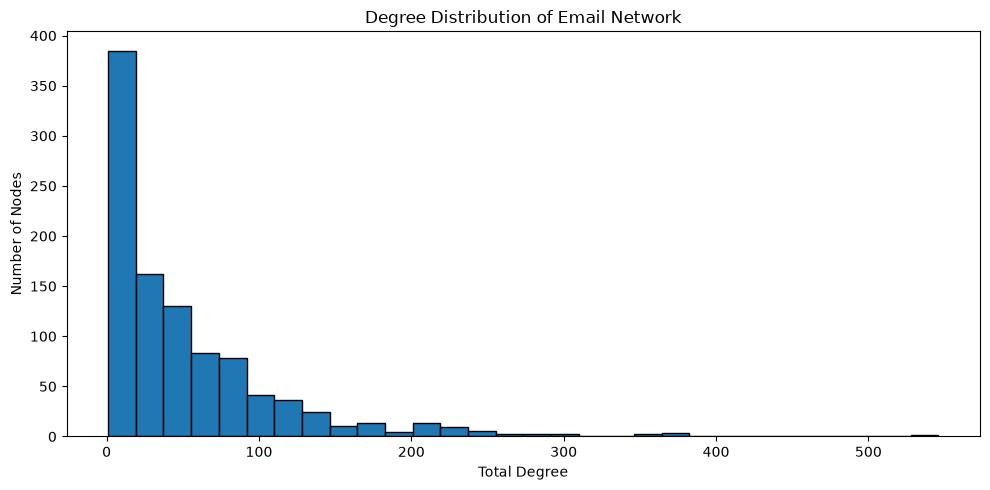

In [17]:
# Calculate total degree for each node
total_degrees = [degree for node, degree in G.degree()]

# Plot degree distribution
plt.figure(figsize=(10, 5))

plt.hist(total_degrees, bins=30, edgecolor="black")

plt.title("Degree Distribution of Email Network")
plt.xlabel("Total Degree")
plt.ylabel("Number of Nodes")

plt.tight_layout()
plt.show()

In [18]:
# Install the community detection library if needed:
# Run this in a separate notebook cell first:
%pip install python-louvain

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for python-louvain: filename=python_louvain-0.16-py3-none-any.whl size=9475 sha256=9be972595c740f84a8e9db3bf7195ef59cb41c9bc2aa0ad38f4c9faf02f9ffa6
  Stored in directory: c:\users\mdsih\appdata\local\pip\cache\wheels\ae\22\72\95110a1ec427d179bc90c8ae1bcf245568db417ac2f34dee63
Successfully built python-louvain
Note: you may need to restart the kernel to use updated packages.


In [19]:
import community as community_louvain

# Convert directed graph to undirected graph
G_undirected = G.to_undirected()

# Detect communities using Louvain algorithm
partition = community_louvain.best_partition(G_undirected)

# Count communities
num_communities = len(set(partition.values()))

print("===== Community Detection Results =====")
print("Total communities:", num_communities)

# Show the size of the 10 largest communities
community_sizes = pd.Series(partition).value_counts()

print("\nTop 10 community sizes:")
print(community_sizes.head(10))

===== Community Detection Results =====
Total communities: 28

Top 10 community sizes:
7     248
1     146
9     129
5     126
4     111
2      93
17     67
13     56
15     10
20      1
Name: count, dtype: int64


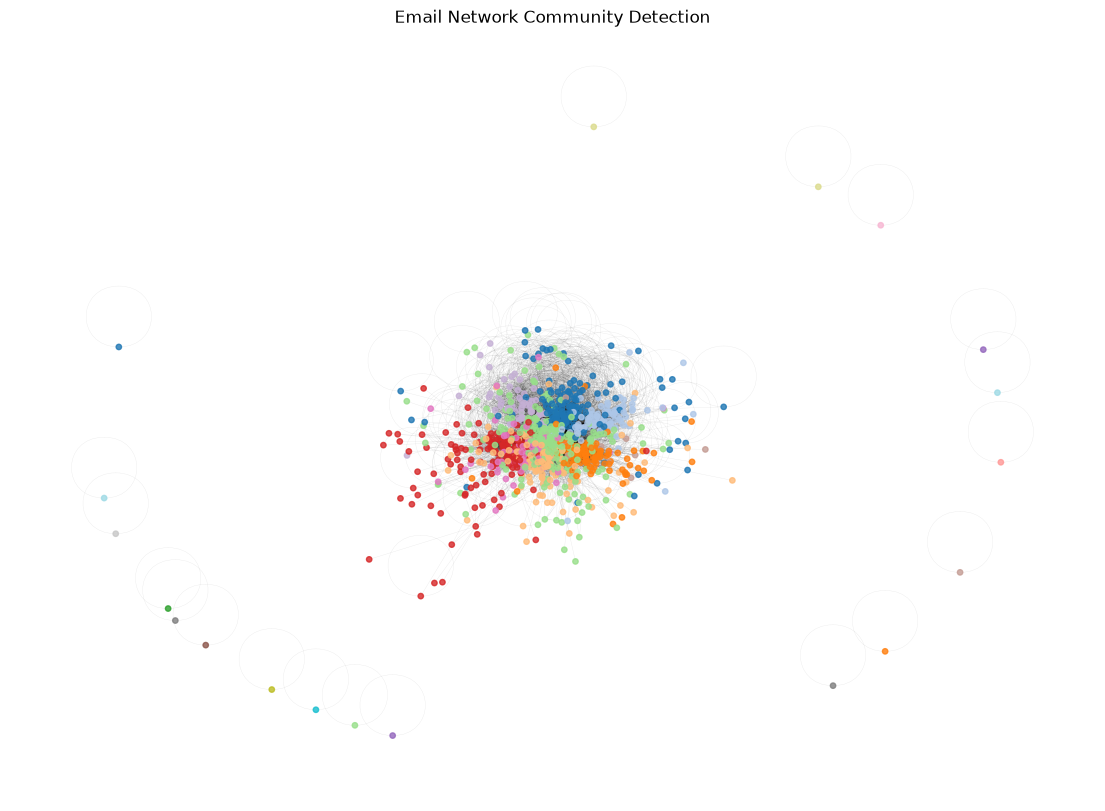

In [22]:
# Assign a color to each node based on its community
node_colors = [partition[node] for node in G_undirected.nodes()]

# Create graph layout
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G_undirected,
    seed=42,
    k=0.15
)

nx.draw_networkx_nodes(
    G_undirected,
    pos,
    node_color=node_colors,
    cmap=plt.cm.tab20,
    node_size=15,
    alpha=0.8
)

nx.draw_networkx_edges(
    G_undirected,
    pos,
    alpha=0.08,
    width=0.3
)

plt.title("Email Network Community Detection")
plt.axis("off")
plt.show()

In [23]:
# Find candidate node pairs that are not directly connected
candidate_pairs = [
    (u, v)
    for u, v in nx.non_edges(G_undirected)
    if u != v
]

print("Total possible non-edge pairs:", len(candidate_pairs))

Total possible non-edge pairs: 488446


In [24]:
# Select one node for link prediction
target_node = 160

# Calculate common-neighbor scores for candidate links
predictions = list(
    nx.common_neighbor_centrality(
        G_undirected,
        ebunch=[
            (target_node, node)
            for node in G_undirected.nodes()
            if node != target_node
            and not G_undirected.has_edge(target_node, node)
        ]
    )
)

# Sort by score in descending order
predictions = sorted(
    predictions,
    key=lambda x: x[2],
    reverse=True
)

print("===== Top 10 Link Prediction Candidates =====")

for node1, node2, score in predictions[:10]:
    print(f"Node {node1} - Node {node2}: Score = {score:.4f}")

===== Top 10 Link Prediction Candidates =====
Node 160 - Node 62: Score = 229.3000
Node 160 - Node 86: Score = 206.9000
Node 160 - Node 434: Score = 202.9000
Node 160 - Node 13: Score = 193.3000
Node 160 - Node 64: Score = 181.3000
Node 160 - Node 5: Score = 178.9000
Node 160 - Node 301: Score = 174.1000
Node 160 - Node 420: Score = 172.5000
Node 160 - Node 211: Score = 166.1000
Node 160 - Node 6: Score = 161.3000


In [25]:
from sklearn.model_selection import train_test_split

# Remove self-loops for a cleaner link prediction experiment
G_clean = G_undirected.copy()
G_clean.remove_edges_from(nx.selfloop_edges(G_clean))

# Split existing edges into train and test sets
all_edges = list(G_clean.edges())

train_edges, test_edges = train_test_split(
    all_edges,
    test_size=0.2,
    random_state=42
)

# Build training graph
G_train = nx.Graph()
G_train.add_nodes_from(G_clean.nodes())
G_train.add_edges_from(train_edges)

print("===== Link Prediction Train/Test Split =====")
print("Total nodes:", G_train.number_of_nodes())
print("Training edges:", len(train_edges))
print("Testing edges:", len(test_edges))
print("Self-loops remaining:", nx.number_of_selfloops(G_train))

===== Link Prediction Train/Test Split =====
Total nodes: 1005
Training edges: 12851
Testing edges: 3213
Self-loops remaining: 0


In [26]:
import random
from sklearn.metrics import roc_auc_score, average_precision_score

# Create positive samples from test edges
positive_edges = test_edges

# Generate an equal number of negative samples
random.seed(42)

negative_edges = []
nodes = list(G_train.nodes())
existing_edges = {tuple(sorted(edge)) for edge in G_clean.edges()}

while len(negative_edges) < len(positive_edges):
    u, v = random.sample(nodes, 2)
    pair = tuple(sorted((u, v)))

    if pair not in existing_edges and pair not in negative_edges:
        negative_edges.append(pair)

# Calculate Common Neighbors scores
def common_neighbors_score(graph, edge_list):
    scores = []
    for u, v in edge_list:
        scores.append(len(list(nx.common_neighbors(graph, u, v))))
    return scores

positive_scores = common_neighbors_score(G_train, positive_edges)
negative_scores = common_neighbors_score(G_train, negative_edges)

# Combine labels and scores
y_true = [1] * len(positive_scores) + [0] * len(negative_scores)
y_scores = positive_scores + negative_scores

# Evaluate
roc_auc = roc_auc_score(y_true, y_scores)
avg_precision = average_precision_score(y_true, y_scores)

print("===== Link Prediction Evaluation =====")
print("Positive test edges:", len(positive_edges))
print("Negative samples:", len(negative_edges))
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Average Precision: {avg_precision:.4f}")

===== Link Prediction Evaluation =====
Positive test edges: 3213
Negative samples: 3213
ROC-AUC: 0.9413
Average Precision: 0.9342


In [27]:
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd

# Generate scores for each method
methods = {
    "Common Neighbors": nx.common_neighbors,
}

positive_edges = list(test_edges)

negative_edges = list(negative_edges)

# Common Neighbors scores
cn_pos = [
    len(list(nx.common_neighbors(G_train, u, v)))
    for u, v in positive_edges
]

cn_neg = [
    len(list(nx.common_neighbors(G_train, u, v)))
    for u, v in negative_edges
]

# Jaccard Coefficient scores
jc_pos = [
    score
    for _, _, score in nx.jaccard_coefficient(G_train, positive_edges)
]

jc_neg = [
    score
    for _, _, score in nx.jaccard_coefficient(G_train, negative_edges)
]

# Preferential Attachment scores
pa_pos = [
    score
    for _, _, score in nx.preferential_attachment(G_train, positive_edges)
]

pa_neg = [
    score
    for _, _, score in nx.preferential_attachment(G_train, negative_edges)
]

# Compare methods
y_true = [1] * len(positive_edges) + [0] * len(negative_edges)

results = []

for name, pos_scores, neg_scores in [
    ("Common Neighbors", cn_pos, cn_neg),
    ("Jaccard Coefficient", jc_pos, jc_neg),
    ("Preferential Attachment", pa_pos, pa_neg),
]:
    scores = pos_scores + neg_scores

    results.append({
        "Method": name,
        "ROC-AUC": roc_auc_score(y_true, scores),
        "Average Precision": average_precision_score(y_true, scores)
    })

results_df = pd.DataFrame(results).sort_values(
    "ROC-AUC",
    ascending=False
)

display(results_df.round(4))

,Method,ROC-AUC,Average Precision
0,Common Neighbors,0.9413,0.9342
1,Jaccard Coefficient,0.9291,0.9263
2,Preferential Attachment,0.8697,0.8683


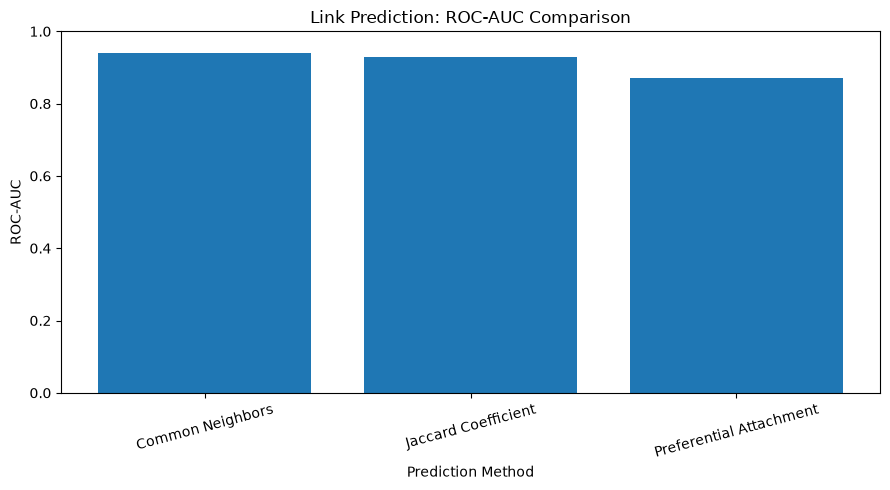

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Method"],
    results_df["ROC-AUC"]
)

plt.title("Link Prediction: ROC-AUC Comparison")
plt.xlabel("Prediction Method")
plt.ylabel("ROC-AUC")
plt.ylim(0, 1)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [30]:
results_df.to_csv("../models/link_prediction_results.csv", index=False)

print("Results saved successfully!")
print(results_df)

Results saved successfully!
                    Method   ROC-AUC  Average Precision
0         Common Neighbors  0.941318           0.934159
1      Jaccard Coefficient  0.929077           0.926317
2  Preferential Attachment  0.869659           0.868343


In [31]:
# Check the current graph and its structure

print("Number of nodes:", G_train.number_of_nodes())
print("Number of edges:", G_train.number_of_edges())
print("Graph is directed:", G_train.is_directed())

Number of nodes: 1005
Number of edges: 12851
Graph is directed: False


In [34]:
import sys
import numpy as np

print("Python version:", sys.version)
print("NumPy version:", np.__version__)

Python version: 3.14.2 (tags/v3.14.2:df79316, Dec  5 2025, 17:18:21) [MSC v.1944 64 bit (AMD64)]
NumPy version: 2.5.4


In [1]:
import sys
print(sys.version)

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [2]:
import pandas as pd
import networkx as nx

# Load the email network dataset
edges = pd.read_csv(
    "../data/raw/email-Eu-core.txt.gz",
    sep=" ",
    compression="gzip",
    header=None,
    names=["source", "target"]
)

# Create an undirected graph
G = nx.from_pandas_edgelist(
    edges,
    source="source",
    target="target",
    create_using=nx.Graph()
)

# Remove self-loops
G.remove_edges_from(nx.selfloop_edges(G))

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 1005
Edges: 16064


In [3]:
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Self-loops:", nx.number_of_selfloops(G))
print("Is directed:", G.is_directed())

Nodes: 1005
Edges: 16064
Self-loops: 0
Is directed: False


In [4]:
from node2vec import Node2Vec

node2vec_model = Node2Vec(
    G,
    dimensions=64,
    walk_length=20,
    num_walks=100,
    workers=1,
    seed=42
)

model = node2vec_model.fit(
    window=10,
    min_count=1,
    batch_words=128
)

print("Node2Vec embeddings created successfully!")
print("Number of node embeddings:", len(model.wv))
print("Embedding dimensions:", model.wv.vector_size)

Computing transition probabilities:   0%|          | 0/1005 [00:00<?, ?it/s]

Generating walks (CPU: 1): 100%|██████████| 100/100 [00:46<00:00,  2.17it/s]


Node2Vec embeddings created successfully!
Number of node embeddings: 1005
Embedding dimensions: 64


In [5]:
# Find nodes most similar to node 160

similar_nodes = model.wv.most_similar("160", topn=10)

print("Top 10 nodes similar to Node 160:\n")

for node, similarity in similar_nodes:
    print(f"Node {node}: Similarity = {similarity:.4f}")

Top 10 nodes similar to Node 160:

Node 107: Similarity = 0.5851
Node 821: Similarity = 0.5255
Node 676: Similarity = 0.5208
Node 882: Similarity = 0.5129
Node 166: Similarity = 0.5118
Node 301: Similarity = 0.4930
Node 62: Similarity = 0.4705
Node 786: Similarity = 0.4585
Node 533: Similarity = 0.4578
Node 857: Similarity = 0.4536


In [6]:
import pandas as pd
import os

# Create a DataFrame from node embeddings
embedding_df = pd.DataFrame(
    [model.wv[str(node)] for node in G.nodes()],
    index=list(G.nodes())
)

embedding_df.index.name = "node_id"

# Save embeddings
os.makedirs("../models", exist_ok=True)

embedding_df.to_csv("../models/node2vec_embeddings.csv")

print("Embeddings saved successfully!")
print("Shape:", embedding_df.shape)
print("Saved to: models/node2vec_embeddings.csv")

Embeddings saved successfully!
Shape: (1005, 64)
Saved to: models/node2vec_embeddings.csv


In [ ]:
from sklearn.model_selection import train_test_split
import networkx as nx

# Get all unique edges
edges_list = list(G.edges())

# Split edges into training and testing sets
train_edges, test_edges = train_test_split(
    edges_list,
    test_size=0.2,
    random_state=42
)

# Create training graph
G_train = nx.Graph()
G_train.add_nodes_from(G.nodes())
G_train.add_edges_from(train_edges)

print("Original graph edges:", len(edges_list))
print("Training edges:", len(train_edges))
print("Testing edges:", len(test_edges))
print("Training graph nodes:", G_train.number_of_nodes())


Original graph edges: 16064
Training edges: 12851
Testing edges: 3213
Training graph nodes: 1005


In [8]:
from node2vec import Node2Vec

# Train Node2Vec using only the training graph
node2vec_train = Node2Vec(
    G_train,
    dimensions=64,
    walk_length=20,
    num_walks=100,
    workers=1,
    seed=42
)

model_train = node2vec_train.fit(
    window=10,
    min_count=1,
    batch_words=128
)

print("Training embeddings created successfully!")
print("Number of node embeddings:", len(model_train.wv))
print("Embedding dimensions:", model_train.wv.vector_size)

Computing transition probabilities:   0%|          | 0/1005 [00:00<?, ?it/s]

Generating walks (CPU: 1): 100%|██████████| 100/100 [00:38<00:00,  2.63it/s]


Training embeddings created successfully!
Number of node embeddings: 1005
Embedding dimensions: 64


In [9]:
import random

# Reproducible results
random.seed(42)

# Positive pairs: edges in the training graph
positive_edges = list(G_train.edges())

# Negative pairs: node pairs with no edge in the original graph
negative_edges = list(nx.non_edges(G))

# Sample the same number of negative pairs as positive pairs
negative_samples = random.sample(
    negative_edges,
    len(positive_edges)
)

print("Positive pairs:", len(positive_edges))
print("Negative pairs:", len(negative_samples))
print("Total pairs:", len(positive_edges) + len(negative_samples))

Positive pairs: 12851
Negative pairs: 12851
Total pairs: 25702


In [11]:
import numpy as np

# Create features for a pair of nodes
def get_edge_features(edges, embedding_model):
    features = []

    for u, v in edges:
        embedding_u = embedding_model.wv[str(u)]
        embedding_v = embedding_model.wv[str(v)]

        # Hadamard product
        features.append(embedding_u * embedding_v)

    return np.array(features)


# Combine positive and negative pairs
all_edges = positive_edges + negative_samples

labels = (
    [1] * len(positive_edges)
    + [0] * len(negative_samples)
)

# Create feature matrix
X = get_edge_features(all_edges, model_train)
y = np.array(labels)

print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Positive labels:", np.sum(y == 1))
print("Negative labels:", np.sum(y == 0))

Feature matrix shape: (25702, 64)
Labels shape: (25702,)
Positive labels: 12851
Negative labels: 12851


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Build a test set using held-out positive edges
test_positive_edges = test_edges

# Sample negative edges for testing
test_negative_edges = random.sample(
    list(nx.non_edges(G)),
    len(test_positive_edges)
)

# Training pairs: training edges + negative samples
train_negative_edges = negative_samples

X_train = get_edge_features(
    positive_edges + train_negative_edges,
    model_train
)

y_train = np.array(
    [1] * len(positive_edges)
    + [0] * len(train_negative_edges)
)

# Test pairs: held-out edges + negative samples
X_test = get_edge_features(
    test_positive_edges + test_negative_edges,
    model_train
)

y_test = np.array(
    [1] * len(test_positive_edges)
    + [0] * len(test_negative_edges)
)

# Train classifier
classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

classifier.fit(X_train, y_train)

# Predict test probabilities and labels
y_pred = classifier.predict(X_test)
y_prob = classifier.predict_proba(X_test)[:, 1]

# Evaluate
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("Average Precision:", round(average_precision_score(y_test, y_prob), 4))

Accuracy: 0.676
Precision: 0.7477
Recall: 0.5313
F1-score: 0.6212
ROC-AUC: 0.7692
Average Precision: 0.7634


In [13]:
# Convert edges to unordered pairs so (u, v) and (v, u)
# are treated as the same undirected edge.

def normalize_edges(edge_list):
    return {
        (min(u, v), max(u, v))
        for u, v in edge_list
    }

all_nodes = list(G.nodes())

# All possible node pairs
all_possible_pairs = set()

for i, u in enumerate(all_nodes):
    for v in all_nodes[i + 1:]:
        all_possible_pairs.add((min(u, v), max(u, v)))

# Remove every real edge from possible negative pairs
all_real_edges = normalize_edges(G.edges())
non_edges = list(all_possible_pairs - all_real_edges)

# Normalize training and testing positive edges
train_positive = list(normalize_edges(train_edges))
test_positive = list(normalize_edges(test_edges))

# Ensure positive splits are disjoint
print("Training positive pairs:", len(train_positive))
print("Testing positive pairs:", len(test_positive))
print(
    "Positive overlap:",
    len(set(train_positive) & set(test_positive))
)
print("Available negative pairs:", len(non_edges))

Training positive pairs: 12851
Testing positive pairs: 3213
Positive overlap: 0
Available negative pairs: 488446


In [14]:
import random

random.seed(42)

# Convert all real edges into a set
real_edges = normalize_edges(G.edges())

# Generate negative samples separately
train_negative = random.sample(
    list(set(non_edges) - set(test_negative_edges))
    if "test_negative_edges" in globals()
    else non_edges,
    len(train_positive)
)

# Remove training negatives before sampling test negatives
remaining_non_edges = list(set(non_edges) - set(train_negative))

test_negative = random.sample(
    remaining_non_edges,
    len(test_positive)
)

# Verify the split
print("Training negative pairs:", len(train_negative))
print("Testing negative pairs:", len(test_negative))
print(
    "Negative overlap:",
    len(set(train_negative) & set(test_negative))
)
print(
    "Training negative-real edge overlap:",
    len(set(train_negative) & real_edges)
)
print(
    "Testing negative-real edge overlap:",
    len(set(test_negative) & real_edges)
)

Training negative pairs: 12851
Testing negative pairs: 3213
Negative overlap: 0
Training negative-real edge overlap: 0
Testing negative-real edge overlap: 0


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import numpy as np

# Create training features and labels
X_train = get_edge_features(
    train_positive + train_negative,
    model_train
)

y_train = np.array(
    [1] * len(train_positive)
    + [0] * len(train_negative)
)

# Create testing features and labels
X_test = get_edge_features(
    test_positive + test_negative,
    model_train
)

y_test = np.array(
    [1] * len(test_positive)
    + [0] * len(test_negative)
)

# Train classifier
classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

classifier.fit(X_train, y_train)

# Predict
y_pred = classifier.predict(X_test)
y_prob = classifier.predict_proba(X_test)[:, 1]

# Evaluate model
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print(
    "Average Precision:",
    round(average_precision_score(y_test, y_prob), 4)
)

Accuracy: 0.6723
Precision: 0.7397
Recall: 0.5316
F1-score: 0.6186
ROC-AUC: 0.7644
Average Precision: 0.758


In [16]:
import pandas as pd
import os

# Store evaluation metrics
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "Average Precision"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob),
        average_precision_score(y_test, y_prob)
    ]
})

# Save results
os.makedirs("../models", exist_ok=True)

results.to_csv(
    "../models/node2vec_link_prediction_results.csv",
    index=False
)

print(results.to_string(index=False))
print("\nResults saved successfully!")
print("File: models/node2vec_link_prediction_results.csv")

           Metric    Score
         Accuracy 0.672269
        Precision 0.739714
           Recall 0.531590
         F1-score 0.618616
          ROC-AUC 0.764368
Average Precision 0.757958

Results saved successfully!
File: models/node2vec_link_prediction_results.csv


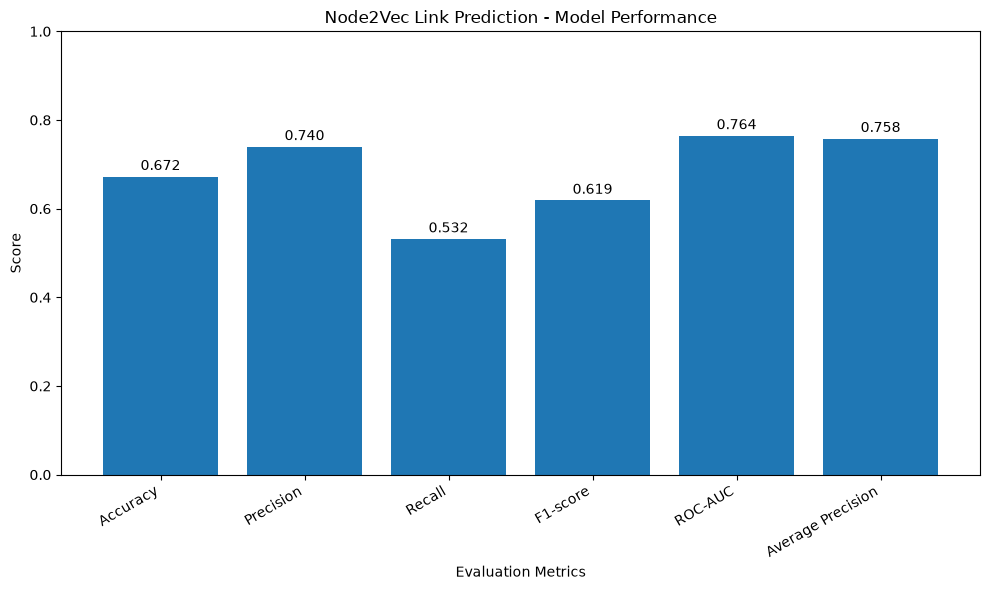

Performance chart saved successfully!
Saved to: models/node2vec_performance.png


In [19]:
import matplotlib.pyplot as plt
import pandas as pd

# Load saved results
results = pd.read_csv(
    "../models/node2vec_link_prediction_results.csv"
)

# Create chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    results["Metric"],
    results["Score"]
)

plt.title("Node2Vec Link Prediction - Model Performance")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)

# Show scores above bars
for bar in bars:
    score = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.015,
        f"{score:.3f}",
        ha="center"
    )

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

# Save chart
plt.savefig(
    "../models/node2vec_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Performance chart saved successfully!")
print("Saved to: models/node2vec_performance.png")

In [20]:
import pandas as pd
import os

# Check whether the previous results file exists
results_path = "../models/link_prediction_results.csv"

if os.path.exists(results_path):
    baseline_results = pd.read_csv(results_path)

    print("Baseline results file found!")
    print("\nAvailable results:")
    print(baseline_results.to_string(index=False))
else:
    print("Baseline results file not found.")

Baseline results file found!

Available results:
                 Method  ROC-AUC  Average Precision
       Common Neighbors 0.941318           0.934159
    Jaccard Coefficient 0.929077           0.926317
Preferential Attachment 0.869659           0.868343


In [21]:
import pandas as pd
import os

# Load baseline results
baseline_results = pd.read_csv(
    "../models/link_prediction_results.csv"
)

# Create Node2Vec results
node2vec_results = pd.DataFrame({
    "Method": ["Node2Vec + Logistic Regression"],
    "ROC-AUC": [roc_auc_score(y_test, y_prob)],
    "Average Precision": [
        average_precision_score(y_test, y_prob)
    ]
})

# Combine all results
comparison = pd.concat(
    [baseline_results, node2vec_results],
    ignore_index=True
)

# Display comparison table
print("MODEL PERFORMANCE COMPARISON\n")
print(comparison.to_string(index=False))

# Save comparison
comparison.to_csv(
    "../models/model_comparison.csv",
    index=False
)

print("\nComparison saved successfully!")
print("File: models/model_comparison.csv")

MODEL PERFORMANCE COMPARISON

                        Method  ROC-AUC  Average Precision
              Common Neighbors 0.941318           0.934159
           Jaccard Coefficient 0.929077           0.926317
       Preferential Attachment 0.869659           0.868343
Node2Vec + Logistic Regression 0.764368           0.757958

Comparison saved successfully!
File: models/model_comparison.csv


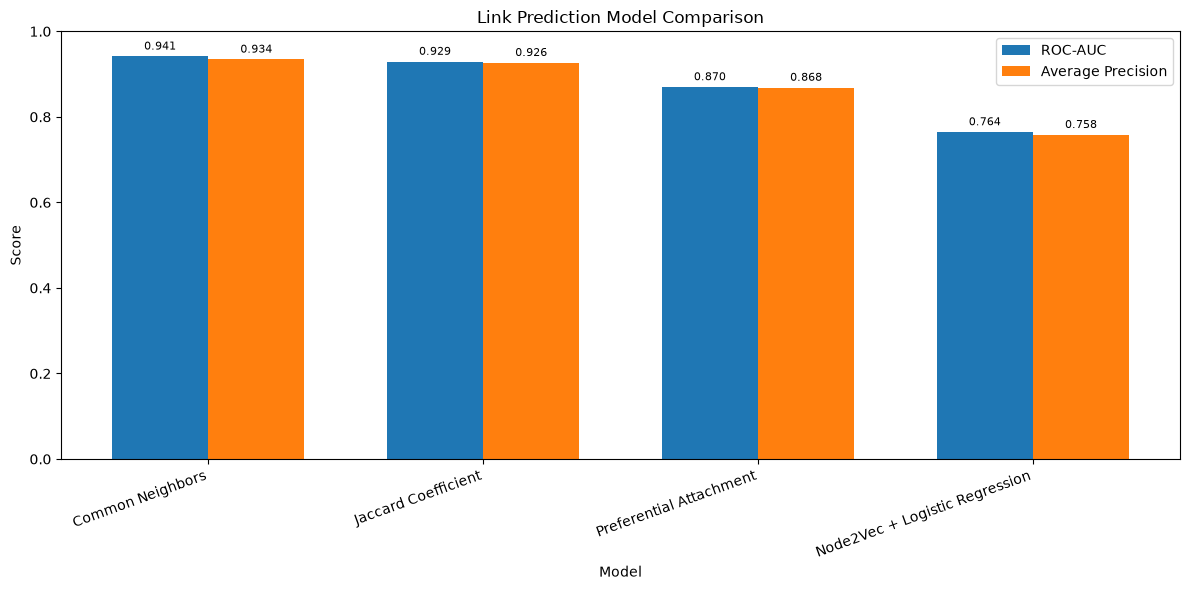

Model comparison chart saved successfully!


In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load comparison results
comparison = pd.read_csv(
    "../models/model_comparison.csv"
)

# Prepare chart
x = np.arange(len(comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

# Plot both metrics
bars1 = ax.bar(
    x - width / 2,
    comparison["ROC-AUC"],
    width,
    label="ROC-AUC"
)

bars2 = ax.bar(
    x + width / 2,
    comparison["Average Precision"],
    width,
    label="Average Precision"
)

# Add labels
ax.set_title("Link Prediction Model Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)

ax.set_xticks(x)
ax.set_xticklabels(
    comparison["Method"],
    rotation=20,
    ha="right"
)

ax.legend()

# Display values
ax.bar_label(bars1, fmt="%.3f", padding=3, fontsize=8)
ax.bar_label(bars2, fmt="%.3f", padding=3, fontsize=8)

plt.tight_layout()

# Save chart
plt.savefig(
    "../models/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison chart saved successfully!")

In [23]:
print("Graph available:", "G" in globals())
print("Training graph available:", "G_train" in globals())
print("Test edges available:", "test_edges" in globals())
print("Node2Vec model available:", "model_train" in globals())

Graph available: True
Training graph available: True
Test edges available: True
Node2Vec model available: True


In [24]:
import numpy as np
import pandas as pd
import networkx as nx

from sklearn.metrics import roc_auc_score, average_precision_score

# Use the same test positives and negatives for all models
eval_positive = test_positive
eval_negative = test_negative

eval_edges = eval_positive + eval_negative
y_eval = np.array(
    [1] * len(eval_positive) + [0] * len(eval_negative)
)

# Create score arrays for baseline methods
baseline_scores = {
    "Common Neighbors": [],
    "Jaccard Coefficient": [],
    "Preferential Attachment": []
}

# Use the training graph only for baseline scores
for u, v in eval_edges:
    cn = list(nx.common_neighbors(G_train, u, v))
    baseline_scores["Common Neighbors"].append(len(cn))

    jaccard = list(nx.jaccard_coefficient(G_train, [(u, v)]))[0][2]
    baseline_scores["Jaccard Coefficient"].append(jaccard)

    pa = list(nx.preferential_attachment(G_train, [(u, v)]))[0][2]
    baseline_scores["Preferential Attachment"].append(pa)

# Node2Vec probabilities from the trained classifier
X_eval = get_edge_features(eval_edges, model_train)
node2vec_scores = classifier.predict_proba(X_eval)[:, 1]

# Calculate metrics for all models
rows = []

for method, scores in baseline_scores.items():
    rows.append({
        "Method": method,
        "ROC-AUC": roc_auc_score(y_eval, scores),
        "Average Precision": average_precision_score(y_eval, scores)
    })

rows.append({
    "Method": "Node2Vec + Logistic Regression",
    "ROC-AUC": roc_auc_score(y_eval, node2vec_scores),
    "Average Precision": average_precision_score(y_eval, node2vec_scores)
})

same_test_comparison = pd.DataFrame(rows)

print("SAME TEST SET MODEL COMPARISON\n")
print(same_test_comparison.round(4).to_string(index=False))

same_test_comparison.to_csv(
    "../models/same_test_model_comparison.csv",
    index=False
)

print("\nSaved to: models/same_test_model_comparison.csv")

SAME TEST SET MODEL COMPARISON

                        Method  ROC-AUC  Average Precision
              Common Neighbors   0.9422             0.9368
           Jaccard Coefficient   0.9321             0.9311
       Preferential Attachment   0.8716             0.8698
Node2Vec + Logistic Regression   0.7644             0.7580

Saved to: models/same_test_model_comparison.csv


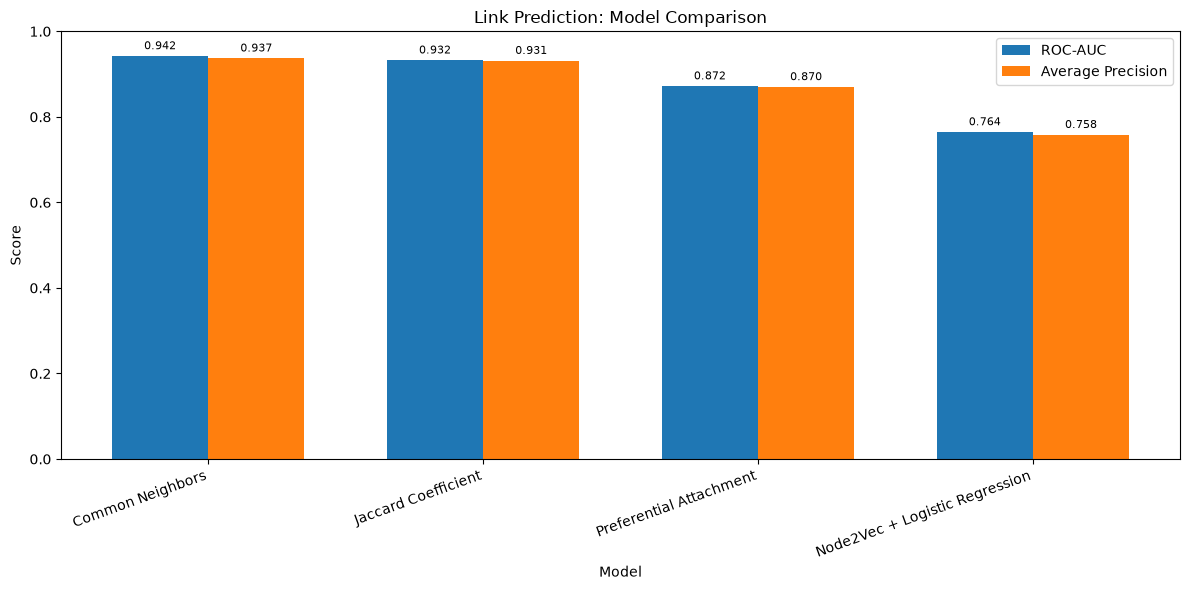

Final comparison chart saved successfully!
File: models/same_test_model_comparison.png


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load fair comparison results
comparison = pd.read_csv(
    "../models/same_test_model_comparison.csv"
)

x = np.arange(len(comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

bars1 = ax.bar(
    x - width / 2,
    comparison["ROC-AUC"],
    width,
    label="ROC-AUC"
)

bars2 = ax.bar(
    x + width / 2,
    comparison["Average Precision"],
    width,
    label="Average Precision"
)

ax.set_title("Link Prediction: Model Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)

ax.set_xticks(x)
ax.set_xticklabels(
    comparison["Method"],
    rotation=20,
    ha="right"
)

ax.legend()

ax.bar_label(bars1, fmt="%.3f", padding=3, fontsize=8)
ax.bar_label(bars2, fmt="%.3f", padding=3, fontsize=8)

plt.tight_layout()

plt.savefig(
    "../models/same_test_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final comparison chart saved successfully!")
print("File: models/same_test_model_comparison.png")

In [26]:
import networkx as nx

# Detect communities using Louvain algorithm
communities = nx.community.louvain_communities(
    G,
    seed=42
)

print("Total communities:", len(communities))

# Show the 10 largest communities
community_sizes = sorted(
    [len(c) for c in communities],
    reverse=True
)

print("\nLargest 10 community sizes:")

for i, size in enumerate(community_sizes[:10], start=1):
    print(f"Community {i}: {size} nodes")

Total communities: 28

Largest 10 community sizes:
Community 1: 190 nodes
Community 2: 157 nodes
Community 3: 145 nodes
Community 4: 127 nodes
Community 5: 125 nodes
Community 6: 109 nodes
Community 7: 91 nodes
Community 8: 32 nodes
Community 9: 10 nodes
Community 10: 1 nodes


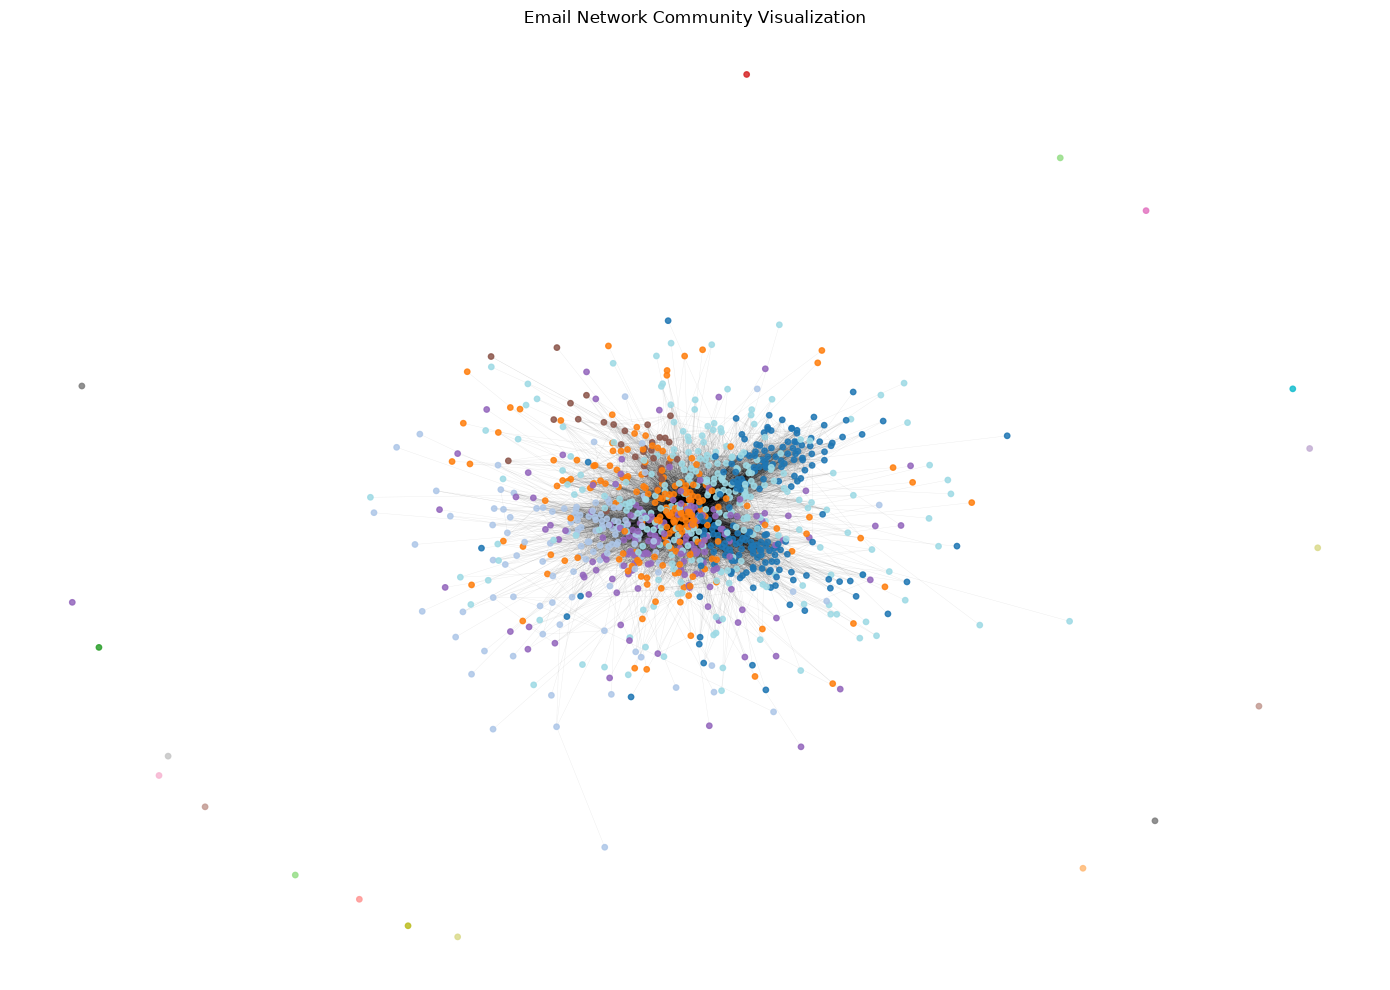

Community visualization saved successfully!
File: models/community_visualization.png


In [27]:
import matplotlib.pyplot as plt
import networkx as nx

# Assign each node to a community
community_map = {}

for community_id, community in enumerate(communities):
    for node in community:
        community_map[node] = community_id

# Create node colors
node_colors = [
    community_map[node]
    for node in G.nodes()
]

# Calculate node positions
pos = nx.spring_layout(
    G,
    seed=42,
    k=0.15,
    iterations=30
)

# Draw the graph
plt.figure(figsize=(14, 10))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color=node_colors,
    cmap=plt.cm.tab20,
    node_size=15,
    alpha=0.85
)

nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.08,
    width=0.3
)

plt.title("Email Network Community Visualization")
plt.axis("off")
plt.tight_layout()

# Save visualization
plt.savefig(
    "../models/community_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Community visualization saved successfully!")
print("File: models/community_visualization.png")